
## Evaluating Age-Related Fairness in Five-Year Breast Cancer Survival Prediction Using Global Decision-Threshold Adjustment


## 1. Imports

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc, classification_report
from sklearn.calibration import CalibrationDisplay
from IPython.display import display
pd.set_option("display.max_columns",100)
METRICS=pd.DataFrame(json.loads(r'''[{"threshold":0.5,"accuracy":0.7942708333,"precision":0.8016528926,"recall":0.9765100671,"f1":0.880484115,"roc_auc":0.7146090214,"brier_score":0.1526499395,"tn":14,"fp":72,"fn":7,"tp":291,"specificity":0.1627906977,"fpr":0.8372093023,"Model":"Logistic Regression","DPD":0.1415497254,"EOD":0.2083333333},{"threshold":0.5,"accuracy":0.7942708333,"precision":0.811965812,"recall":0.9563758389,"f1":0.8782742681,"roc_auc":0.7171453098,"brier_score":0.15668791,"tn":20,"fp":66,"fn":13,"tp":285,"specificity":0.2325581395,"fpr":0.7674418605,"Model":"Random Forest","DPD":0.225747407,"EOD":0.4916666667},{"threshold":0.5,"accuracy":0.7916666667,"precision":0.8168604651,"recall":0.9429530201,"f1":0.8753894081,"roc_auc":0.7321679413,"brier_score":0.1539110162,"tn":23,"fp":63,"fn":17,"tp":281,"specificity":0.2674418605,"fpr":0.7325581395,"Model":"XGBoost","DPD":0.1989017694,"EOD":0.2316513761},{"threshold":0.4,"accuracy":0.796875,"precision":0.8021978022,"recall":0.9798657718,"f1":0.8821752266,"roc_auc":0.7321679413,"brier_score":0.1539110162,"tn":14,"fp":72,"fn":6,"tp":292,"specificity":0.1627906977,"fpr":0.8372093023,"Model":"XGBoost","DPD":0.0894152796,"EOD":0.1833333333}]'''))
AGE_METRICS=pd.DataFrame(json.loads(r'''[{"Model":"Logistic Regression @ 0.50","Age group":"Middle (40-65)","n":213,"Survival positive n":173,"Survival negative n":40,"Selection rate":0.9483568075,"TPR":0.9768786127,"FPR":0.825,"Brier score":0.1355621095},{"Model":"Logistic Regression @ 0.50","Age group":"Older (>65)","n":149,"Survival positive n":109,"Survival negative n":40,"Selection rate":0.9597315436,"TPR":0.9908256881,"FPR":0.875,"Brier score":0.1773924846},{"Model":"Logistic Regression @ 0.50","Age group":"Young (<40)","n":22,"Survival positive n":16,"Survival negative n":6,"Selection rate":0.8181818182,"TPR":0.875,"FPR":0.6666666667,"Brier score":0.150516692},{"Model":"Random Forest @ 0.50","Age group":"Middle (40-65)","n":213,"Survival positive n":173,"Survival negative n":40,"Selection rate":0.9061032864,"TPR":0.936416185,"FPR":0.775,"Brier score":0.1403999751},{"Model":"Random Forest @ 0.50","Age group":"Older (>65)","n":149,"Survival positive n":109,"Survival negative n":40,"Selection rate":0.9530201342,"TPR":1.0,"FPR":0.825,"Brier score":0.1800691816},{"Model":"Random Forest @ 0.50","Age group":"Young (<40)","n":22,"Survival positive n":16,"Survival negative n":6,"Selection rate":0.7272727273,"TPR":0.875,"FPR":0.3333333333,"Brier score":0.1560297591},{"Model":"XGBoost @ 0.50","Age group":"Middle (40-65)","n":213,"Survival positive n":173,"Survival negative n":40,"Selection rate":0.8920187793,"TPR":0.936416185,"FPR":0.7,"Brier score":0.1376128616},{"Model":"XGBoost @ 0.50","Age group":"Older (>65)","n":149,"Survival positive n":109,"Survival negative n":40,"Selection rate":0.9261744966,"TPR":0.9816513761,"FPR":0.775,"Brier score":0.1754042174},{"Model":"XGBoost @ 0.50","Age group":"Young (<40)","n":22,"Survival positive n":16,"Survival negative n":6,"Selection rate":0.7272727273,"TPR":0.75,"FPR":0.6666666667,"Brier score":0.1661391955},{"Model":"XGBoost @ 0.40 (validation-selected)","Age group":"Middle (40-65)","n":213,"Survival positive n":173,"Survival negative n":40,"Selection rate":0.9530516432,"TPR":0.9768786127,"FPR":0.85,"Brier score":0.1376128616},{"Model":"XGBoost @ 0.40 (validation-selected)","Age group":"Older (>65)","n":149,"Survival positive n":109,"Survival negative n":40,"Selection rate":0.9530201342,"TPR":0.9908256881,"FPR":0.85,"Brier score":0.1754042174},{"Model":"XGBoost @ 0.40 (validation-selected)","Age group":"Young (<40)","n":22,"Survival positive n":16,"Survival negative n":6,"Selection rate":0.8636363636,"TPR":0.9375,"FPR":0.6666666667,"Brier score":0.1661391955}]'''))
COHORT_FLOW=pd.DataFrame(json.loads(r'''[{"Stage":"Source CSV records","Count":2509},{"Stage":"Exact duplicate rows removed","Count":0},{"Stage":"Records after duplicate removal","Count":2509},{"Stage":"Records missing survival time or status","Count":528},{"Stage":"Living\/censored or unresolved follow-up under 60 months excluded","Count":64},{"Stage":"Retained labelled records","Count":1917}]'''))
VALIDATION_THRESHOLDS=pd.DataFrame(json.loads(r'''[{"threshold":0.2,"accuracy":0.78125,"precision":0.7806788512,"recall":1.0,"f1":0.8768328446,"roc_auc":0.7541609286,"brier_score":0.1465103073,"tn":1,"fp":84,"fn":0,"tp":299,"DPD":0.0526315789,"EOD":0.1428571429},{"threshold":0.25,"accuracy":0.7786458333,"precision":0.780104712,"recall":0.9966555184,"f1":0.8751835536,"roc_auc":0.7541609286,"brier_score":0.1465103073,"tn":1,"fp":84,"fn":1,"tp":298,"DPD":0.0526315789,"EOD":0.1428571429},{"threshold":0.3,"accuracy":0.7864583333,"precision":0.7893333333,"recall":0.9899665552,"f1":0.8783382789,"roc_auc":0.7541609286,"brier_score":0.1465103073,"tn":6,"fp":79,"fn":3,"tp":296,"DPD":0.14281936,"EOD":0.2431610942},{"threshold":0.35,"accuracy":0.7916666667,"precision":0.7967479675,"recall":0.983277592,"f1":0.880239521,"roc_auc":0.7541609286,"brier_score":0.1465103073,"tn":10,"fp":75,"fn":5,"tp":294,"DPD":0.1277742549,"EOD":0.2218844985},{"threshold":0.4,"accuracy":0.7864583333,"precision":0.797260274,"recall":0.9732441472,"f1":0.8765060241,"roc_auc":0.7541609286,"brier_score":0.1465103073,"tn":11,"fp":74,"fn":8,"tp":291,"DPD":0.1176937318,"EOD":0.2006079027},{"threshold":0.45,"accuracy":0.7916666667,"precision":0.8067226891,"recall":0.9632107023,"f1":0.8780487805,"roc_auc":0.7541609286,"brier_score":0.1465103073,"tn":16,"fp":69,"fn":11,"tp":288,"DPD":0.2029169309,"EOD":0.3009118541},{"threshold":0.5,"accuracy":0.7942708333,"precision":0.8197674419,"recall":0.9431438127,"f1":0.8771384137,"roc_auc":0.7541609286,"brier_score":0.1465103073,"tn":23,"fp":62,"fn":17,"tp":282,"DPD":0.2253372124,"EOD":0.2158054711},{"threshold":0.55,"accuracy":0.7890625,"precision":0.828313253,"recall":0.9197324415,"f1":0.8716323296,"roc_auc":0.7541609286,"brier_score":0.1465103073,"tn":28,"fp":57,"fn":24,"tp":275,"DPD":0.2479391249,"EOD":0.2661064426},{"threshold":0.6,"accuracy":0.78125,"precision":0.8328173375,"recall":0.8996655518,"f1":0.8649517685,"roc_auc":0.7541609286,"brier_score":0.1465103073,"tn":31,"fp":54,"fn":30,"tp":269,"DPD":0.280349114,"EOD":0.3326330532}]'''))
BOOTSTRAP_CI=pd.DataFrame(json.loads(r'''[{"Metric":"DPD","Threshold 0.50 estimate":0.1989017694,"Selected threshold":0.4,"Selected threshold estimate":0.0894152796,"Difference selected minus 0.50":-0.1094864898,"Paired bootstrap 95% CI lower":-0.2525930445,"Paired bootstrap 95% CI upper":0.0252206344,"Bootstrap proportion difference < 0":0.9311,"Replicates":10000,"Seed":42},{"Metric":"EOD","Threshold 0.50 estimate":0.2316513761,"Selected threshold":0.4,"Selected threshold estimate":0.1833333333,"Difference selected minus 0.50":-0.0483180428,"Paired bootstrap 95% CI lower":-0.2991590214,"Paired bootstrap 95% CI upper":0.15,"Bootstrap proportion difference < 0":0.5622,"Replicates":10000,"Seed":42}]'''))
PREDICTIONS=json.loads(r'''{"y_test":[1,1,0,0,1,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,0,1,1,1,1,0,1,1,1,1,1,0,1,1,1,0,1,0,1,1,1,1,0,0,1,0,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,0,0,1,1,1,1,1,1,0,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,0,0,0,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,0,0,1,0,1,1,0,1,1,0,1,1,1,1,1,1,0,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,0,1,1,0,1,0,0,0,1,1,0,1,1,1,1,0,1,1,1,1,0,1,1,1,0,0,1,1,1,1,1,1,0,1,1,1,1,1,0,0,1,0,0,0,1,1,1,1,0,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,1,0,0,1,0,1,1,1,1,0,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1],"age_test":["Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Young (<40)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Older (>65)","Young (<40)","Middle (40-65)","Young (<40)","Middle (40-65)","Older (>65)","Middle (40-65)","Older (>65)","Young (<40)","Older (>65)","Older (>65)","Older (>65)","Middle (40-65)","Older (>65)","Older (>65)","Older (>65)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Young (<40)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Older (>65)","Older (>65)","Older (>65)","Older (>65)","Middle (40-65)","Young (<40)","Middle (40-65)","Older (>65)","Middle (40-65)","Older (>65)","Young (<40)","Older (>65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Older (>65)","Older (>65)","Older (>65)","Middle (40-65)","Older (>65)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Young (<40)","Middle (40-65)","Older (>65)","Middle (40-65)","Older (>65)","Young (<40)","Older (>65)","Older (>65)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Young (<40)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Older (>65)","Older (>65)","Older (>65)","Older (>65)","Older (>65)","Older (>65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Older (>65)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Older (>65)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Older (>65)","Middle (40-65)","Young (<40)","Older (>65)","Older (>65)","Older (>65)","Older (>65)","Middle (40-65)","Older (>65)","Older (>65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Older (>65)","Middle (40-65)","Older (>65)","Older (>65)","Middle (40-65)","Middle (40-65)","Young (<40)","Young (<40)","Older (>65)","Older (>65)","Middle (40-65)","Older (>65)","Older (>65)","Young (<40)","Middle (40-65)","Older (>65)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Older (>65)","Older (>65)","Older (>65)","Middle (40-65)","Older (>65)","Older (>65)","Middle (40-65)","Older (>65)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Older (>65)","Young (<40)","Older (>65)","Middle (40-65)","Older (>65)","Middle (40-65)","Young (<40)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Older (>65)","Older (>65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Older (>65)","Middle (40-65)","Older (>65)","Older (>65)","Young (<40)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Older (>65)","Young (<40)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Young (<40)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Older (>65)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Young (<40)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Older (>65)","Older (>65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Older (>65)","Older (>65)","Older (>65)","Older (>65)","Middle (40-65)","Older (>65)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Older (>65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Older (>65)","Older (>65)","Middle (40-65)","Older (>65)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Young (<40)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Middle (40-65)","Older (>65)","Young (<40)","Older (>65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Older (>65)","Older (>65)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)","Middle (40-65)","Older (>65)","Middle (40-65)"],"chosen_threshold":[0.4],"prob_Logistic_Regression":[0.8559187093154326,0.9202742755376048,0.6429266965766086,0.9164820828079946,0.929219465737888,0.8589047448536948,0.9731232647819413,0.6582908645945745,0.9300134593284596,0.8714340007410969,0.8509890207758147,0.96132760149198,0.6302045294411994,0.9139887977541751,0.7845292513623039,0.8825687394324959,0.3337506936370331,0.8027565108563129,0.7902080346469262,0.842597247530968,0.8276343501914546,0.9311593706722752,0.9487730961574279,0.8811491067765366,0.8231046499473098,0.6877815215040473,0.8902799947547054,0.8618955757027007,0.8851845455709498,0.942670444947034,0.5912178771377092,0.7837597078366196,0.693518062933284,0.36280122103765367,0.8937440449391131,0.8324533277161551,0.5260430129007072,0.9602007504747079,0.6632167522468632,0.588839978331744,0.7420081473738922,0.7912634961599833,0.9588776396770164,0.6459268377818901,0.5170083850870534,0.8194143869668751,0.811663991192312,0.9458094501394587,0.6916765875459717,0.7359517547587165,0.8831893254066191,0.8975257400504258,0.9423396206604499,0.7744146071122345,0.7015612852688679,0.8042012968638379,0.9180919170672536,0.8603601284659446,0.6400885009843864,0.907989646646037,0.9207568471246748,0.6563774297229222,0.5970919933290684,0.8150212049297245,0.6498254709818081,0.7327567864486719,0.7022478312386843,0.6905123223801395,0.9506701367185794,0.6562783384775128,0.9266515175294653,0.8399344181988296,0.8898199554189491,0.7716477861001734,0.699060876723892,0.8287673624550556,0.9424968345611979,0.7932807960379307,0.5372801135678399,0.9261525628156968,0.9390760181262845,0.8312396928779512,0.9279426770858257,0.2903514759985095,0.8396045775590412,0.8803518889537313,0.9452923191587564,0.85150476360052,0.8778662009446861,0.9683403808649181,0.9022470460979308,0.85079307906195,0.8797269963010051,0.9219785808388101,0.828038823691037,0.7729883809636658,0.7580863166070405,0.5182822598964962,0.8494829991283644,0.8284647991881947,0.8887527405821856,0.5587249097795148,0.9363632509044874,0.6589481557290225,0.8882941627612034,0.9426872459331662,0.7390932699304595,0.867088464399726,0.6833244767760559,0.7262347130725444,0.6928011222433035,0.7317650436920287,0.7573331245748205,0.6213481226933752,0.8576983850744091,0.801581634571843,0.9197851478155684,0.7265637281102366,0.9390160546518364,0.9294246217610105,0.6251410685688018,0.8680521780880419,0.9434153557010961,0.7700282029139439,0.8501969952652345,0.7402705912368288,0.8169197890313943,0.899765069202493,0.9541801282565946,0.8326832812979386,0.790489434823962,0.688349598779811,0.880277385770269,0.7128225761877981,0.5830878248160791,0.5831683249792038,0.8277970141806806,0.8498127291759701,0.8829598404893171,0.8707573840499433,0.9130922272189613,0.8919677861351987,0.9242786846897402,0.5940384283715728,0.8669572787016601,0.6619688730548305,0.9381840993060648,0.874037926748267,0.5484588706557791,0.9107828055893402,0.6526711366074841,0.8870398471377837,0.8075697623521789,0.7817633100662521,0.7939750186236528,0.7704497674770682,0.4375041611095854,0.7780791751578736,0.5111586864266675,0.9130292444365784,0.8581724763614724,0.7415774845650227,0.9529277219006889,0.5737065413623355,0.763071444272251,0.9162684789594747,0.8888207355328712,0.8642442199685392,0.5326821263584393,0.654037490032654,0.5164902289096743,0.4443277811100087,0.7287241584616758,0.8455517261453073,0.775228542960291,0.8919599062890916,0.8599725107559046,0.5966917103815147,0.9445115030830452,0.864640557058429,0.9733558039895269,0.3447008375641239,0.9446278486318702,0.865801237190763,0.6340370062103763,0.836614695921704,0.9700268816089893,0.8634378014293516,0.8625780781047565,0.9147093190746265,0.8882976699519108,0.9412596763685502,0.5388100482231304,0.7219430950522682,0.7032814250461255,0.9036021051791822,0.776347915430122,0.5222474179533777,0.9255500077262037,0.5284317964533951,0.7482827990905382,0.7507812600190451,0.6874535450986988,0.8821437420336925,0.9346840500704006,0.9259005469877235,0.8004479649468043,0.8678875003568751,0.5638652185433287,0.9030285307968422,0.2222168614558602,0.6778450185179806,0.6170647742558937,0.8888062404892978,0.8741807231035651,0.8064171196713876,0.860830803591396,0.8841463164954081,0.924115258026995,0.9399159666093597,0.9492677701656226,0.9543820484277167,0.8460171481201954,0.9324204358254787,0.5021494832858446,0.9350403527792491,0.7795414966306504,0.696635626123512,0.60129518698534,0.9725985979635887,0.8790922661316968,0.3899094116529205,0.7043246031772432,0.4775102645467839,0.8795799662929054,0.548217656563811,0.5424273801687785,0.5047736171879841,0.938569826941256,0.5826445578949055,0.7681327491226266,0.8063066661264783,0.7691447533033571,0.9225720203733578,0.44425770799689956,0.6774045056440094,0.932933325305385,0.9304930796854086,0.6355555742985075,0.921789021873185,0.6086760827383875,0.4715500205548378,0.8037247819955308,0.9605427150441719,0.6218383830182145,0.9514419046425745,0.9174139109326651,0.8657548529283575,0.6909665418504124,0.8289858351745596,0.8606491732436246,0.9165916562261787,0.5559559207398419,0.630692975482756,0.7368646505136395,0.8105069919698191,0.9410164046862455,0.7351655588476177,0.8287085731004288,0.8704795501085476,0.4950498980560906,0.846323829335376,0.9412711691553275,0.3475791366701023,0.9594725710369858,0.7488858702071005,0.9201797554342548,0.74453850819421,0.6257368286364632,0.9515860585151753,0.7739317628246544,0.3906048037169035,0.9629024471890194,0.9016974326574734,0.5160191595270969,0.583416564444222,0.614143557199725,0.31289091112271056,0.8596745938985052,0.8083881626064345,0.8073839247231746,0.5937190313534468,0.8127697084413243,0.8047472983435431,0.8533483354478544,0.9521505047059609,0.5934412268339099,0.9387485265814798,0.9398911662184981,0.8610532128311812,0.8975089472750281,0.6726132858852658,0.8431130357198032,0.6920559790768365,0.4312730369952551,0.6073307506580183,0.831318996216627,0.5637885158200543,0.7128527463980892,0.9128605379342576,0.8129435598803959,0.9297685188910677,0.8957683982444554,0.7295291573668278,0.9451515257826053,0.6640962204228982,0.8955322800667659,0.9247074570979966,0.6944175552958746,0.8644662127886084,0.8831275199793701,0.6739810212695485,0.6093983486781502,0.9377603854467517,0.9199676432258045,0.9097187512552338,0.864668681902107,0.6520354241464351,0.6508065094610928,0.8502832975648359,0.17314015680147182,0.7066807378323037,0.8033033708690219,0.7850455993723765,0.4384665030411789,0.4486574117985966,0.8930798907092762,0.8227264196766292,0.7323377881307871,0.6901191553064632,0.6401638697317867,0.8892714735081383,0.5312949344061269,0.9425056570578176,0.8510399802128464,0.9533072675694676,0.969547536174965,0.9544148135048035,0.626514191768069,0.5863112235950549,0.14676608428958285,0.7119184230250211,0.7036456775541241,0.9244901471179021,0.8345883219521602,0.9675328965330424,0.9149870041840058,0.9398001911765634,0.9189034554924089,0.8108964664755673,0.8892994349844707,0.7623017066243684,0.6859441437687547,0.9368370225713692,0.8812589162501547,0.8958595243321276,0.861958068893325,0.9327907460228195,0.5822290878108181,0.7889617152692117,0.8596001316115084,0.936511972158455,0.9414490376528469,0.8780750677921371,0.8184918412040533,0.6877529007395863,0.8238587146279213,0.36702392903731595,0.7543799570600153,0.7299831748525317,0.9594874374795272,0.9754221485838952,0.5813396206313333,0.5584102027877228],"prob_Random_Forest":[0.7269172805376553,0.9732864198143312,0.7407662912219698,0.9397854518003329,0.9636682088308623,0.8052652772990427,0.9543304956770569,0.6731003004713056,0.9035220678109528,0.7257097409924386,0.8870592586254398,0.9666052467419717,0.5826962092330986,0.9180764616119096,0.7464386553917892,0.9456038362363638,0.36123576483968306,0.8519279941727558,0.8251494178895168,0.8811566813138947,0.7497204166587699,0.962527841477018,0.9427511912361287,0.8820661771770283,0.729028802215432,0.5192372907419419,0.923953955386679,0.8252322617467233,0.9000083061505297,0.9863148858467241,0.5730085649867088,0.7432183834829685,0.637720125598652,0.21616865614914535,0.892242508348789,0.9247928747652192,0.3154655162501031,0.9657337971535473,0.5999558534251647,0.6805940544879706,0.6866974329302902,0.8226748216113186,0.9787453293768767,0.5255456289777594,0.5830115033264691,0.7456675555172062,0.8677094028900405,0.9809610688707114,0.7686690520116479,0.7461323638931077,0.8853485928202839,0.9492922679588189,0.9444862162530957,0.9004907408935856,0.5012339254275584,0.8565471949190495,0.9234453208700769,0.8979303931222851,0.6017164614928577,0.8704326416882259,0.8949639774109113,0.691601165238432,0.5862462660543328,0.7715454762342143,0.5525177098768814,0.8371870881633895,0.7717489602352139,0.8995778462037801,0.8349902797185308,0.6867832888798889,0.9491972833508495,0.7748610957792195,0.8495993050192042,0.6200226511224275,0.6299325790813117,0.8367376792990697,0.9509215345641238,0.7799220297535018,0.6642083635286792,0.9125037500037194,0.8781283366865251,0.8918502200292603,0.9422801658781274,0.47875358826355346,0.9031104788709107,0.7593214061652094,0.9844539595784697,0.7740792347519241,0.9499519056100706,0.9387253523373729,0.9388899511035873,0.8126025135801881,0.9389304046797169,0.899994042223971,0.8042484304466412,0.8443897361247917,0.5988450062802427,0.44049096791757075,0.8615336406446308,0.7914473140511299,0.7489305560945269,0.48145426136913516,0.9499288535233322,0.5770389145504831,0.8145938638278359,0.9818541869284567,0.9350462154588882,0.8139671600200241,0.4293786568147873,0.7561006103826118,0.7289662808907359,0.6625483242612661,0.798479292683666,0.5324087720852276,0.8568014499421079,0.8405356857201244,0.8825491589052622,0.7701176662904003,0.9648615109382377,0.9604496727511308,0.6909566518468071,0.8737262204884405,0.9671619115848796,0.8509398555586203,0.6951808146463082,0.7531059616314983,0.832401777482652,0.945637630535204,0.9612854190278332,0.8632536838010552,0.8646721773258906,0.6805640429078368,0.8159594563944119,0.670945011154297,0.3836736766735827,0.6699866642559236,0.8567809859370756,0.8804491288904529,0.8348813056307758,0.8479128540873134,0.9598184346964901,0.9336636767431797,0.9251116356517574,0.8523882968635246,0.9434763515921907,0.7790988403328488,0.9499288535233322,0.8876120280780984,0.6491083897006675,0.8415192291856672,0.577764159874638,0.9524594447476159,0.7260296247712763,0.7681760626903175,0.8090221373431449,0.8068668992420182,0.5763020023467845,0.8315776564761318,0.5335873126788406,0.8663760418997002,0.9241467981313923,0.765253166553534,0.9595773456487042,0.6038928424262789,0.7376466063195353,0.9530793439366542,0.8289478104898845,0.8596897876134371,0.72787042154031,0.49475594331722145,0.6182147057928328,0.4298200419728653,0.6228809740033231,0.8496284515839204,0.665517299141688,0.8443924654706438,0.8537331357913822,0.6903103477208087,0.9882345037513308,0.8482522002867462,0.956864598989703,0.42069930610127576,0.9705471763308331,0.8443298011530861,0.7430128050101872,0.766801540811563,0.9648743432939861,0.8853527488742584,0.875903975360668,0.9262031810535468,0.9303767905812995,0.9803531617533838,0.5280478828101912,0.7620145226355473,0.7338125841795944,0.919149588736954,0.769662666590892,0.6734486407628058,0.8825689630857912,0.5908900988019414,0.6241936936061936,0.79727709408949,0.6090440549444817,0.8593801513933907,0.9507162969631073,0.9457324880288007,0.8177048881335582,0.8020022215607528,0.3354493089541357,0.8536027367286643,0.3092777035688995,0.7456551475869027,0.7801751734769915,0.9384618199935589,0.9456395791867765,0.8598078790408628,0.8034672193776425,0.9212365437823706,0.9414378278321606,0.9577873513610945,0.9173756306327456,0.9688788579127073,0.924458056008563,0.9383316874810673,0.49527622065300014,0.9774547384969481,0.8615649642389462,0.6844147958114013,0.7287519211708097,0.9714037586858099,0.869311839202214,0.2098229712725591,0.7650461689918646,0.6388651213893752,0.8412620930759961,0.41424941002873306,0.6566147678738732,0.4386690462789879,0.9790278480896092,0.3916135085227214,0.6176979839724208,0.8541902921240363,0.751924420625865,0.896837817340308,0.4276629480146078,0.7030138639992418,0.9697643960736473,0.8913748426730579,0.7589296298802204,0.8988020414024447,0.5023971551359596,0.4099925602524963,0.8464692162264577,0.9528952970953999,0.8223696764132064,0.9552978445075881,0.9653592867697861,0.9001935528298349,0.7774806621899459,0.8482984799082928,0.9108807511573345,0.9289758818636222,0.5234688998810455,0.5059955523127351,0.7530493336646396,0.7318659540941849,0.9478961138583828,0.6598364619858691,0.8651592394710056,0.8823835294802101,0.5984705141494804,0.7954828636886379,0.8829337576021575,0.41800127279463595,0.965360335584085,0.7544374249602318,0.8566365537786079,0.7940290139917423,0.6421352435593518,0.9407649730662878,0.823742501668064,0.6298616481328547,0.965239897299071,0.8950835544294584,0.31235480867565457,0.7575952655041749,0.522386608604736,0.2376513059615516,0.8202036020897471,0.7682837617921088,0.699795824646581,0.673369256189859,0.8390291601990727,0.8179377994258591,0.7808664178312044,0.9675490946268194,0.757229367097661,0.8705801934232987,0.9085322575709611,0.9192694340122296,0.9046755415001426,0.7805628709940217,0.8804187833467938,0.6910020825925755,0.5330093324623337,0.5523899842616184,0.8930457735064564,0.6572508101409117,0.5766865951578534,0.9453484219377287,0.8587195775255927,0.8922475716036748,0.8627617175381372,0.4974348716876911,0.9028251692431223,0.6593725568792006,0.8708480971681551,0.9369357099733081,0.9129588258341345,0.8874015290963894,0.8370805020809567,0.6598326700927547,0.4958337192245882,0.9126327735514594,0.9808742976692586,0.9516386267988334,0.8262609312048366,0.6555200437219888,0.761780324986006,0.8549057169635078,0.21570692024805482,0.7696030601192929,0.7348887765434395,0.8669130470174292,0.6952740644318687,0.25589059597827213,0.938119345762275,0.7427940524684782,0.7489335312695609,0.7413513250852836,0.5429745576059709,0.9046693098213429,0.6425929040984647,0.9835448686693787,0.9266794950301204,0.9042683134582228,0.9753503659604814,0.9812807621442089,0.5140510357375264,0.49815932612477765,0.3219392816035669,0.8723476299720349,0.4980098164120851,0.9772476286743219,0.6328398837863777,0.9602066894523708,0.9477064011803943,0.9342261333339724,0.8893741558672883,0.8484671393767595,0.8866423591907596,0.8021137086080422,0.7258457524383001,0.944550367846094,0.9131036911837996,0.7988827298536576,0.8234390539553135,0.9427773107512374,0.47515713567656503,0.6766783746343741,0.900170256135945,0.9840539595784696,0.9528054417469878,0.893042251526423,0.7362249580737742,0.8516716289131645,0.7422012575856926,0.4492312832331398,0.556893748823951,0.5336318362988403,0.9800455603890067,0.9753324518977057,0.4009127557474854,0.5158316294553351],"prob_XGBoost":[0.830051600933075,0.9382510185241699,0.7043640613555908,0.9243663549423218,0.9616633057594299,0.9150713086128235,0.9600943326950073,0.6971234679222107,0.9316657781600952,0.924788236618042,0.9196479916572571,0.96195387840271,0.5348178744316101,0.9464341998100281,0.7501897215843201,0.9263134002685547,0.28339508175849915,0.8731890916824341,0.8767094612121582,0.9006738662719727,0.896485447883606,0.938324511051178,0.932358980178833,0.9293509721755981,0.7972269058227539,0.5783330202102661,0.936983585357666,0.8703556656837463,0.9006056189537048,0.9667280912399292,0.5208235383033752,0.796330988407135,0.652691662311554,0.23081348836421967,0.8896063566207886,0.8296068906784058,0.4010149836540222,0.948599636554718,0.5590028166770935,0.6661640405654907,0.7651435136795044,0.8567689657211304,0.966481626033783,0.500392735004425,0.3034835159778595,0.7421003580093384,0.857941746711731,0.9631224870681763,0.8090168833732605,0.5663676857948303,0.9215628504753113,0.924582839012146,0.960648775100708,0.826011061668396,0.5987186431884766,0.9071317315101624,0.9206878542900085,0.9313688278198242,0.6974846720695496,0.9352380037307739,0.917607307434082,0.5491161346435547,0.584782600402832,0.7836116552352905,0.7056112885475159,0.7642922401428223,0.8063544631004333,0.8151425719261169,0.9563371539115906,0.7151927947998047,0.9328212738037109,0.8140883445739746,0.8917199969291687,0.5952647924423218,0.6505200862884521,0.8400540947914124,0.9684765934944153,0.7926340699195862,0.5689926743507385,0.9404863715171814,0.9592510461807251,0.8694092035293579,0.9475076198577881,0.45240795612335205,0.8861318826675415,0.8637959957122803,0.9516849517822266,0.7437812089920044,0.9361245036125183,0.9580104947090149,0.9365192651748657,0.8583381175994873,0.9263134002685547,0.9205361008644104,0.8545714020729065,0.8453329801559448,0.30744996666908264,0.5403270125389099,0.8990803956985474,0.8188825845718384,0.7535900473594666,0.47945937514305115,0.9575433135032654,0.4980314075946808,0.841888427734375,0.9464479088783264,0.9038733243942261,0.9035136103630066,0.5177862048149109,0.678379476070404,0.7255829572677612,0.6777271628379822,0.8237205147743225,0.4859287142753601,0.8548275828361511,0.8466916084289551,0.9233788847923279,0.817015528678894,0.9656102657318115,0.9412963390350342,0.669834315776825,0.8871488571166992,0.9488810896873474,0.8350302577018738,0.8518461585044861,0.6903641819953918,0.8069695830345154,0.913205623626709,0.9561668038368225,0.8741700053215027,0.878791332244873,0.6486759781837463,0.8505135178565979,0.5715985894203186,0.44932180643081665,0.6060504913330078,0.8712443709373474,0.8771249651908875,0.8853825330734253,0.8962824940681458,0.9511798024177551,0.9327454566955566,0.9365057349205017,0.7651750445365906,0.934414803981781,0.7390393614768982,0.9575433135032654,0.900132954120636,0.6180205345153809,0.9046216607093811,0.5018169283866882,0.9448609948158264,0.7295224666595459,0.746041476726532,0.7244366407394409,0.8488959670066833,0.593015730381012,0.8565651178359985,0.3555605411529541,0.8955541253089905,0.9349673986434937,0.8073990941047668,0.9563376903533936,0.5772061347961426,0.7888309955596924,0.9486104846000671,0.8548059463500977,0.8528542518615723,0.7044405937194824,0.5829904079437256,0.675864577293396,0.36444091796875,0.664549708366394,0.9006386399269104,0.6073559522628784,0.821327805519104,0.9033896327018738,0.7067210674285889,0.9669760465621948,0.9011257290840149,0.9577569365501404,0.5039111971855164,0.954179584980011,0.8967564702033997,0.6924046277999878,0.9255461692810059,0.9663523435592651,0.9128957390785217,0.8907354474067688,0.9186252355575562,0.9153309464454651,0.9345348477363586,0.4323441684246063,0.6951173543930054,0.7977895736694336,0.9102948307991028,0.7238199710845947,0.522905707359314,0.8577194809913635,0.5503528714179993,0.7153449058532715,0.7936121225357056,0.5983662009239197,0.830535352230072,0.9498969316482544,0.9157764315605164,0.7699801325798035,0.8699580430984497,0.48465603590011597,0.9222146272659302,0.1862933486700058,0.7777358293533325,0.734222412109375,0.931475043296814,0.9287504553794861,0.8449277877807617,0.8335309624671936,0.9157002568244934,0.9478713870048523,0.9510493278503418,0.9302806854248047,0.9495058655738831,0.8970515727996826,0.9256682991981506,0.5230003595352173,0.9592598080635071,0.8614556789398193,0.6989976763725281,0.7203445434570312,0.9644571542739868,0.9210109114646912,0.17182432115077972,0.791861355304718,0.5210575461387634,0.8863562941551208,0.3500085473060608,0.5245928168296814,0.4312244653701782,0.9480210542678833,0.6158391237258911,0.663177490234375,0.8345226049423218,0.6848861575126648,0.9197444319725037,0.20996952056884766,0.7662431001663208,0.9488864541053772,0.9360248446464539,0.6530981063842773,0.9378830790519714,0.43844926357269287,0.34371218085289,0.8736557364463806,0.9433343410491943,0.5901601910591125,0.9414747953414917,0.9293198585510254,0.8892627954483032,0.7081322073936462,0.8708153963088989,0.9093264937400818,0.9364724159240723,0.5137558579444885,0.5625565052032471,0.779789388179779,0.7237738370895386,0.9566051363945007,0.7374709844589233,0.8886290192604065,0.8796538710594177,0.41845670342445374,0.8718785047531128,0.9380609393119812,0.27552536129951477,0.9552714228630066,0.6384555101394653,0.8980661630630493,0.8016712069511414,0.4766509234905243,0.9383277893066406,0.7872260212898254,0.5254610776901245,0.9477049112319946,0.8756150007247925,0.34093043208122253,0.8060526847839355,0.47452202439308167,0.25485697388648987,0.8637735843658447,0.6979600787162781,0.7680280208587646,0.6609596610069275,0.8273023366928101,0.860674262046814,0.8714268803596497,0.9363316297531128,0.7455105781555176,0.9200067520141602,0.9078869223594666,0.9242190718650818,0.9350439310073853,0.6986961960792542,0.9267963767051697,0.8094266653060913,0.43165478110313416,0.46029844880104065,0.8953289985656738,0.6645618677139282,0.6550135612487793,0.9197948575019836,0.8737248778343201,0.9280010461807251,0.9104130864143372,0.3918564021587372,0.9404158592224121,0.6169682741165161,0.9179568290710449,0.9316827654838562,0.7995069622993469,0.8929885625839233,0.8643676042556763,0.6097428798675537,0.49629417061805725,0.9258958697319031,0.9491279125213623,0.9245898723602295,0.8838697671890259,0.7982931137084961,0.716178834438324,0.8548716902732849,0.16010451316833496,0.7649477124214172,0.8222941756248474,0.8805360198020935,0.7086543440818787,0.34651440382003784,0.9333829879760742,0.7709326148033142,0.8332353234291077,0.7124086022377014,0.5044228434562683,0.9270665645599365,0.6648596525192261,0.9488120079040527,0.8992524147033691,0.9576613903045654,0.971070408821106,0.9498637914657593,0.5304381251335144,0.4525550901889801,0.2817680835723877,0.8847588300704956,0.6394748687744141,0.9586306810379028,0.49874064326286316,0.9575150012969971,0.944355309009552,0.9432209134101868,0.9350950717926025,0.8364790081977844,0.9034256339073181,0.8026042580604553,0.6795259714126587,0.9480778574943542,0.9404760599136353,0.7915970683097839,0.8124327063560486,0.9536328911781311,0.3739017844200134,0.6963089108467102,0.9115282893180847,0.9555650949478149,0.9429042339324951,0.9125142097473145,0.8161811828613281,0.8654391169548035,0.8673591017723083,0.4657615125179291,0.6578735113143921,0.547412097454071,0.9564861059188843,0.9569541215896606,0.21090614795684814,0.46603822708129883]}''')
y_test=np.asarray(PREDICTIONS['y_test'],dtype=int)
prob_lr=np.asarray(PREDICTIONS['prob_Logistic_Regression'],dtype=float)
prob_rf=np.asarray(PREDICTIONS['prob_Random_Forest'],dtype=float)
prob_xgb=np.asarray(PREDICTIONS['prob_XGBoost'],dtype=float)
print('Embedded held-out test records:',len(y_test))
display(METRICS)

Embedded held-out test records: 384


,threshold,accuracy,precision,recall,f1,roc_auc,brier_score,tn,fp,fn,tp,specificity,fpr,Model,DPD,EOD
0,0.5,0.794271,0.801653,0.976510,0.880484,0.714609,0.152650,14,72,7,291,0.162791,0.837209,Logistic Regression,0.141550,0.208333
1,0.5,0.794271,0.811966,0.956376,0.878274,0.717145,0.156688,20,66,13,285,0.232558,0.767442,Random Forest,0.225747,0.491667
2,0.5,0.791667,0.816860,0.942953,0.875389,0.732168,0.153911,23,63,17,281,0.267442,0.732558,XGBoost,0.198902,0.231651
3,0.4,0.796875,0.802198,0.979866,0.882175,0.732168,0.153911,14,72,6,292,0.162791,0.837209,XGBoost,0.089415,0.183333


## 2. Cohort flow

,Stage,Count
0,Source CSV records,2509
1,Exact duplicate rows removed,0
2,Records after duplicate removal,2509
3,Records missing survival time or status,528
4,Living/censored or unresolved follow-up under ...,64
5,Retained labelled records,1917


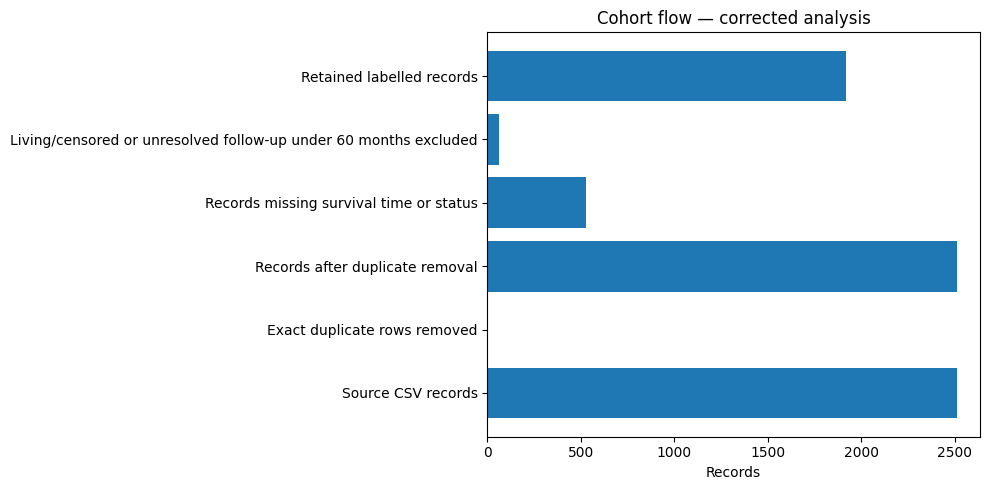

In [2]:
display(COHORT_FLOW)
plt.figure(figsize=(10,5)); plt.barh(COHORT_FLOW['Stage'],COHORT_FLOW['Count']); plt.xlabel('Records'); plt.title('Cohort flow — corrected analysis'); plt.tight_layout(); plt.show()

## 3. Overall model comparison

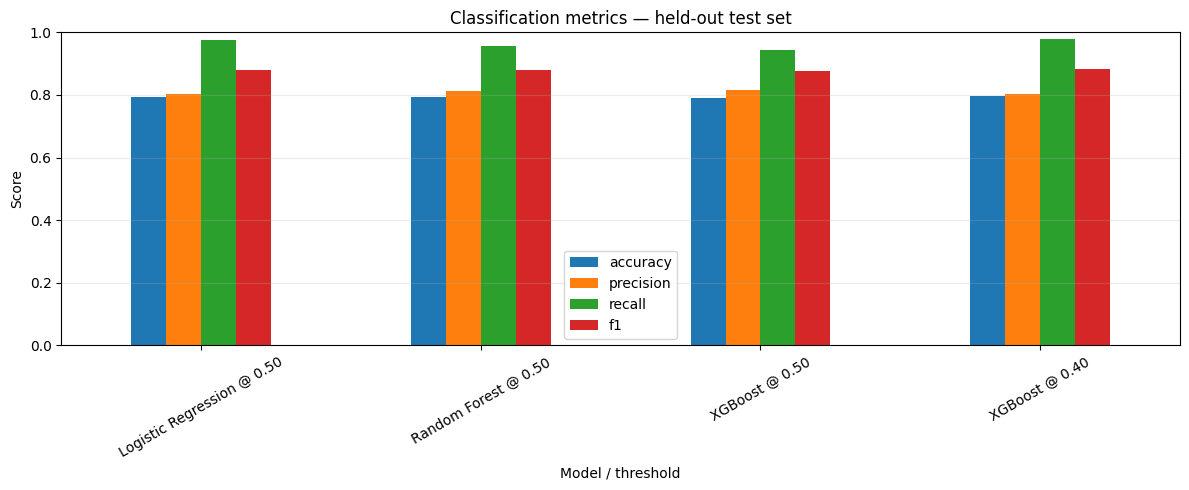

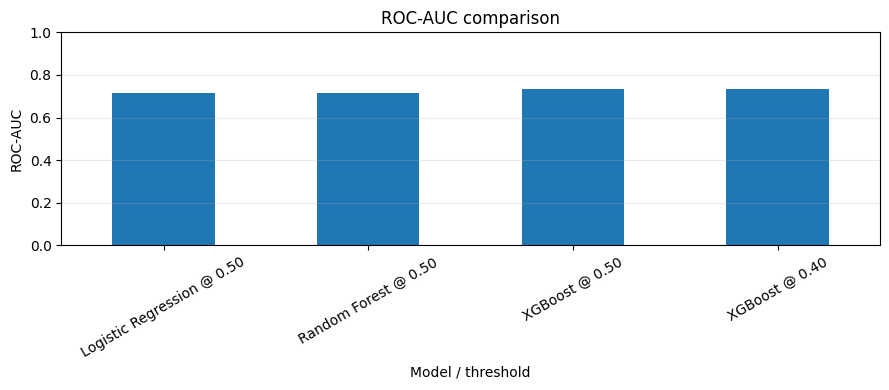

,threshold,accuracy,precision,recall,f1,roc_auc,brier_score,tn,fp,fn,tp,specificity,fpr,Model,DPD,EOD,Model / threshold
0,0.5,0.794271,0.801653,0.976510,0.880484,0.714609,0.152650,14,72,7,291,0.162791,0.837209,Logistic Regression,0.141550,0.208333,Logistic Regression @ 0.50
1,0.5,0.794271,0.811966,0.956376,0.878274,0.717145,0.156688,20,66,13,285,0.232558,0.767442,Random Forest,0.225747,0.491667,Random Forest @ 0.50
2,0.5,0.791667,0.816860,0.942953,0.875389,0.732168,0.153911,23,63,17,281,0.267442,0.732558,XGBoost,0.198902,0.231651,XGBoost @ 0.50
3,0.4,0.796875,0.802198,0.979866,0.882175,0.732168,0.153911,14,72,6,292,0.162791,0.837209,XGBoost,0.089415,0.183333,XGBoost @ 0.40


In [3]:
METRICS['Model / threshold']=METRICS['Model'].astype(str)+' @ '+METRICS['threshold'].map(lambda x:f'{x:.2f}')
ax=METRICS.set_index('Model / threshold')[['accuracy','precision','recall','f1']].plot(kind='bar',figsize=(12,5),ylim=(0,1)); ax.set_title('Classification metrics — held-out test set'); ax.set_ylabel('Score'); ax.tick_params(axis='x',rotation=30); ax.grid(axis='y',alpha=.25); plt.tight_layout(); plt.show()
ax=METRICS.set_index('Model / threshold')[['roc_auc']].plot(kind='bar',figsize=(9,4),ylim=(0,1),legend=False); ax.set_title('ROC-AUC comparison'); ax.set_ylabel('ROC-AUC'); ax.tick_params(axis='x',rotation=30); ax.grid(axis='y',alpha=.25); plt.tight_layout(); plt.show()
display(METRICS)

## 4. Confusion matrices and classification reports

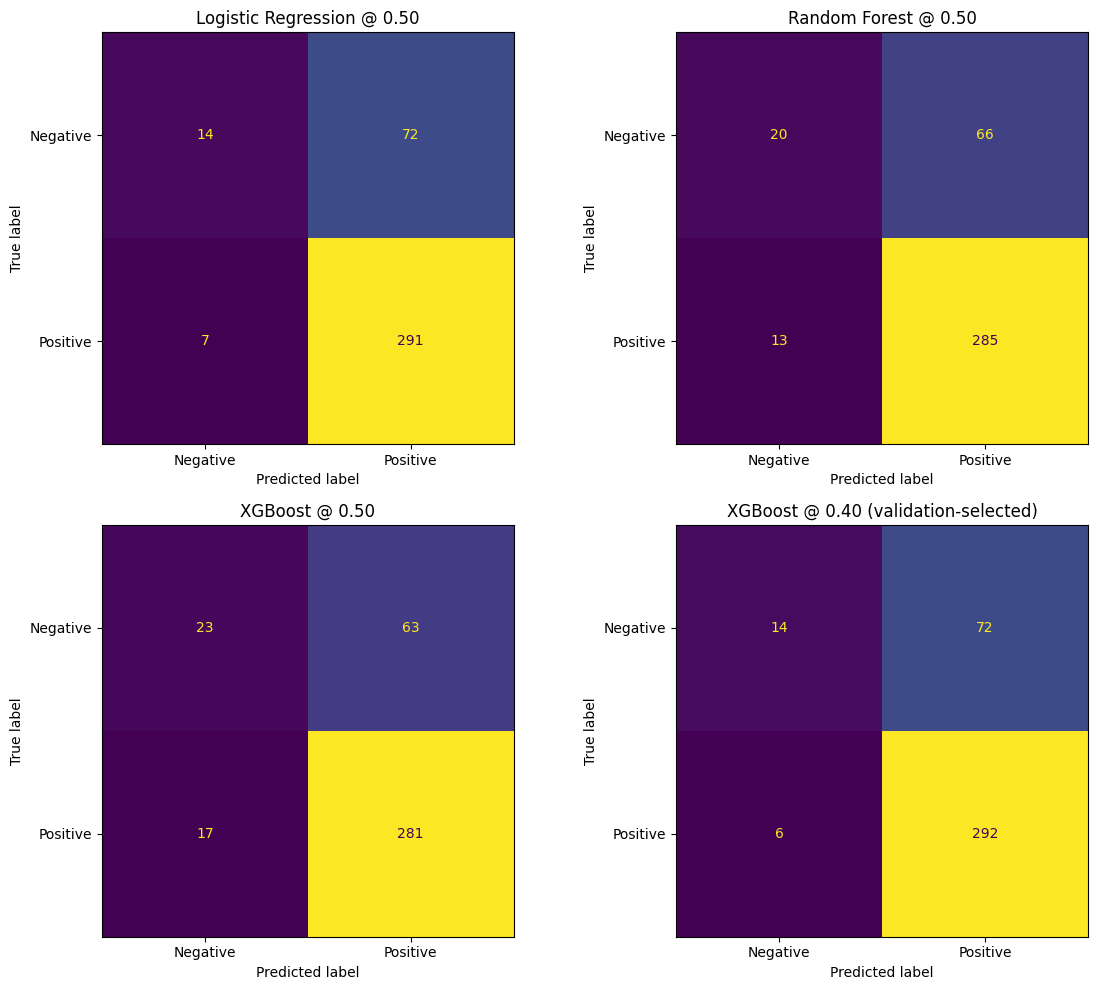


Logistic Regression @ 0.50
              precision    recall  f1-score   support

    Negative       0.67      0.16      0.26        86
    Positive       0.80      0.98      0.88       298

    accuracy                           0.79       384
   macro avg       0.73      0.57      0.57       384
weighted avg       0.77      0.79      0.74       384


Random Forest @ 0.50
              precision    recall  f1-score   support

    Negative       0.61      0.23      0.34        86
    Positive       0.81      0.96      0.88       298

    accuracy                           0.79       384
   macro avg       0.71      0.59      0.61       384
weighted avg       0.77      0.79      0.76       384


XGBoost @ 0.50
              precision    recall  f1-score   support

    Negative       0.57      0.27      0.37        86
    Positive       0.82      0.94      0.88       298

    accuracy                           0.79       384
   macro avg       0.70      0.61      0.62       384
weighted

In [4]:
def labels_at(prob,threshold): return (np.asarray(prob)>=threshold).astype(int)
runs=[('Logistic Regression @ 0.50',prob_lr,.5),('Random Forest @ 0.50',prob_rf,.5),('XGBoost @ 0.50',prob_xgb,.5),('XGBoost @ 0.40 (validation-selected)',prob_xgb,.4)]
fig,axes=plt.subplots(2,2,figsize=(12,10))
for ax,(name,prob,t) in zip(axes.flat,runs):
    cm=confusion_matrix(y_test,labels_at(prob,t),labels=[0,1])
    ConfusionMatrixDisplay(cm,display_labels=['Negative','Positive']).plot(ax=ax,values_format='d',colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()
for name,prob,t in runs:
    print('\n'+name); print(classification_report(y_test,labels_at(prob,t),target_names=['Negative','Positive'],zero_division=0))

## 5. ROC curves

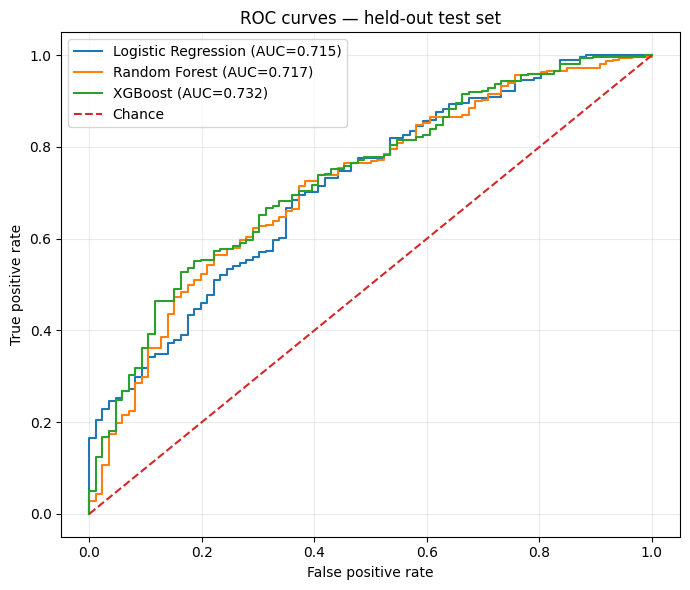

In [5]:
plt.figure(figsize=(7,6))
for name,prob in [('Logistic Regression',prob_lr),('Random Forest',prob_rf),('XGBoost',prob_xgb)]:
    fpr,tpr,_=roc_curve(y_test,prob); plt.plot(fpr,tpr,label=f'{name} (AUC={auc(fpr,tpr):.3f})')
plt.plot([0,1],[0,1],'--',label='Chance'); plt.xlabel('False positive rate'); plt.ylabel('True positive rate'); plt.title('ROC curves — held-out test set'); plt.legend(); plt.grid(alpha=.25); plt.tight_layout(); plt.show()

## 6. Calibration curves

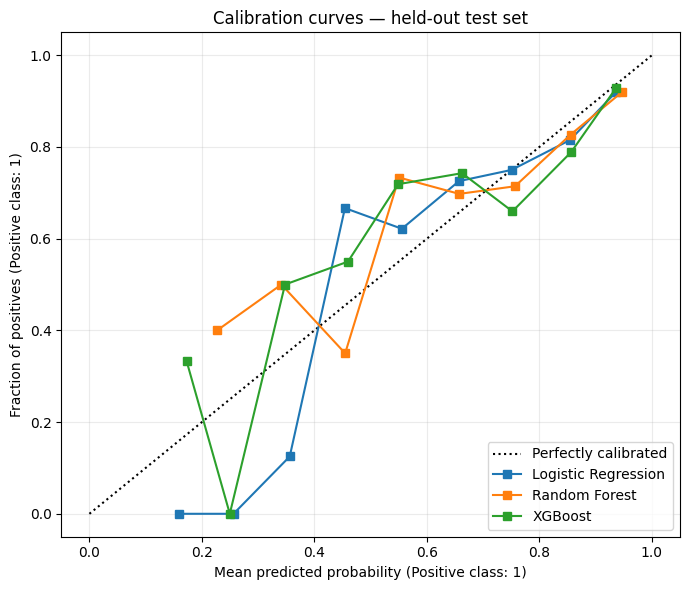

In [6]:
fig,ax=plt.subplots(figsize=(7,6))
CalibrationDisplay.from_predictions(y_test,prob_lr,n_bins=10,name='Logistic Regression',ax=ax)
CalibrationDisplay.from_predictions(y_test,prob_rf,n_bins=10,name='Random Forest',ax=ax)
CalibrationDisplay.from_predictions(y_test,prob_xgb,n_bins=10,name='XGBoost',ax=ax)
ax.set_title('Calibration curves — held-out test set'); ax.grid(alpha=.25); plt.tight_layout(); plt.show()

## 7. Validation-only global threshold selection

,threshold,accuracy,precision,recall,f1,roc_auc,brier_score,tn,fp,fn,tp,DPD,EOD
0,0.20,0.781250,0.780679,1.000000,0.876833,0.754161,0.14651,1,84,0,299,0.052632,0.142857
1,0.25,0.778646,0.780105,0.996656,0.875184,0.754161,0.14651,1,84,1,298,0.052632,0.142857
2,0.30,0.786458,0.789333,0.989967,0.878338,0.754161,0.14651,6,79,3,296,0.142819,0.243161
3,0.35,0.791667,0.796748,0.983278,0.880240,0.754161,0.14651,10,75,5,294,0.127774,0.221884
4,0.40,0.786458,0.797260,0.973244,0.876506,0.754161,0.14651,11,74,8,291,0.117694,0.200608
5,0.45,0.791667,0.806723,0.963211,0.878049,0.754161,0.14651,16,69,11,288,0.202917,0.300912
6,0.50,0.794271,0.819767,0.943144,0.877138,0.754161,0.14651,23,62,17,282,0.225337,0.215805
7,0.55,0.789062,0.828313,0.919732,0.871632,0.754161,0.14651,28,57,24,275,0.247939,0.266106
8,0.60,0.781250,0.832817,0.899666,0.864952,0.754161,0.14651,31,54,30,269,0.280349,0.332633


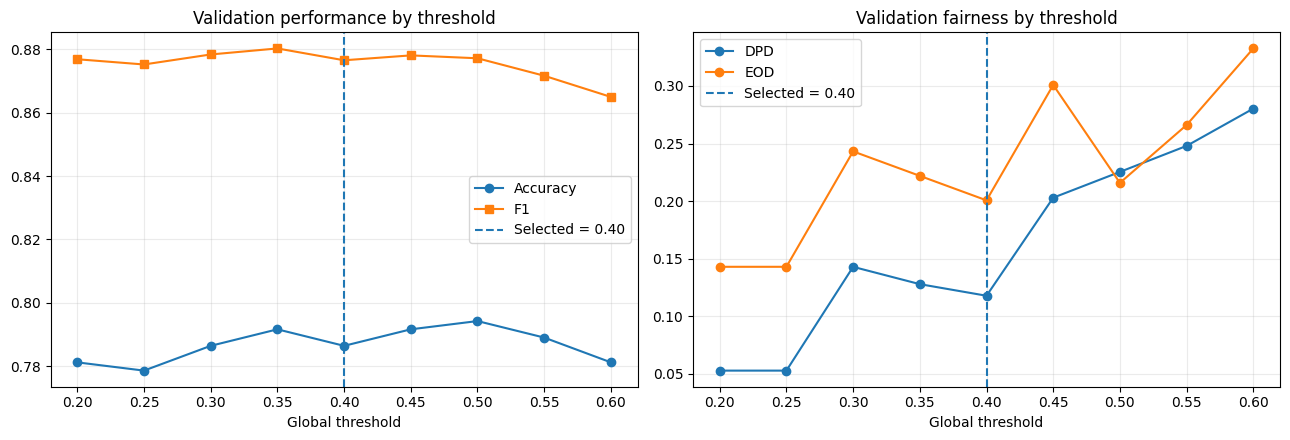

In [7]:
display(VALIDATION_THRESHOLDS)
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
axes[0].plot(VALIDATION_THRESHOLDS['threshold'],VALIDATION_THRESHOLDS['accuracy'],marker='o',label='Accuracy')
if 'f1' in VALIDATION_THRESHOLDS: axes[0].plot(VALIDATION_THRESHOLDS['threshold'],VALIDATION_THRESHOLDS['f1'],marker='s',label='F1')
axes[0].axvline(.40,ls='--',label='Selected = 0.40'); axes[0].set_title('Validation performance by threshold'); axes[0].set_xlabel('Global threshold'); axes[0].legend(); axes[0].grid(alpha=.25)
for col in ['DPD','EOD']:
    if col in VALIDATION_THRESHOLDS: axes[1].plot(VALIDATION_THRESHOLDS['threshold'],VALIDATION_THRESHOLDS[col],marker='o',label=col)
axes[1].axvline(.40,ls='--',label='Selected = 0.40'); axes[1].set_title('Validation fairness by threshold'); axes[1].set_xlabel('Global threshold'); axes[1].legend(); axes[1].grid(alpha=.25)
plt.tight_layout(); plt.show()

## 8. Age-group fairness metrics

,Model,Age group,n,Survival positive n,Survival negative n,Selection rate,TPR,FPR,Brier score
0,Logistic Regression @ 0.50,Middle (40-65),213,173,40,0.948357,0.976879,0.825000,0.135562
1,Logistic Regression @ 0.50,Older (>65),149,109,40,0.959732,0.990826,0.875000,0.177392
2,Logistic Regression @ 0.50,Young (<40),22,16,6,0.818182,0.875000,0.666667,0.150517
3,Random Forest @ 0.50,Middle (40-65),213,173,40,0.906103,0.936416,0.775000,0.140400
4,Random Forest @ 0.50,Older (>65),149,109,40,0.953020,1.000000,0.825000,0.180069
5,Random Forest @ 0.50,Young (<40),22,16,6,0.727273,0.875000,0.333333,0.156030
6,XGBoost @ 0.50,Middle (40-65),213,173,40,0.892019,0.936416,0.700000,0.137613
7,XGBoost @ 0.50,Older (>65),149,109,40,0.926174,0.981651,0.775000,0.175404
8,XGBoost @ 0.50,Young (<40),22,16,6,0.727273,0.750000,0.666667,0.166139
9,XGBoost @ 0.40 (validation-selected),Middle (40-65),213,173,40,0.953052,0.976879,0.850000,0.137613


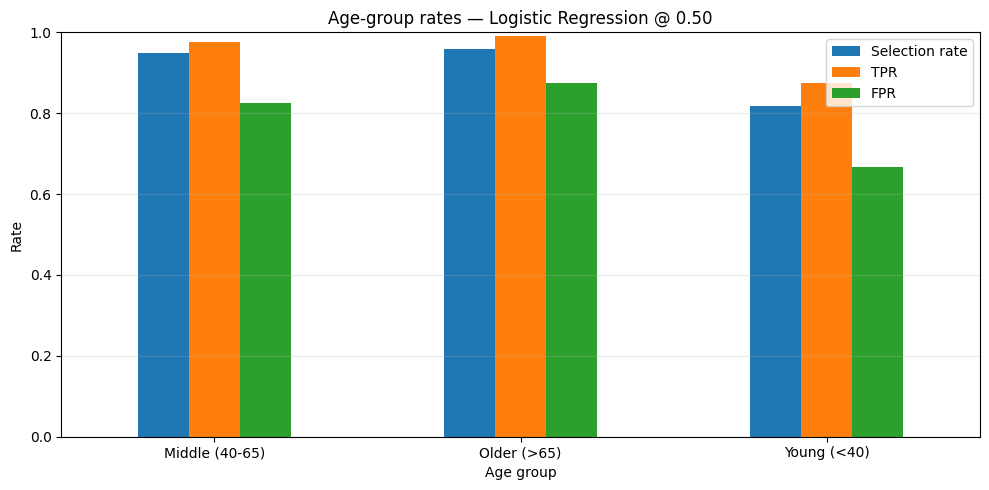

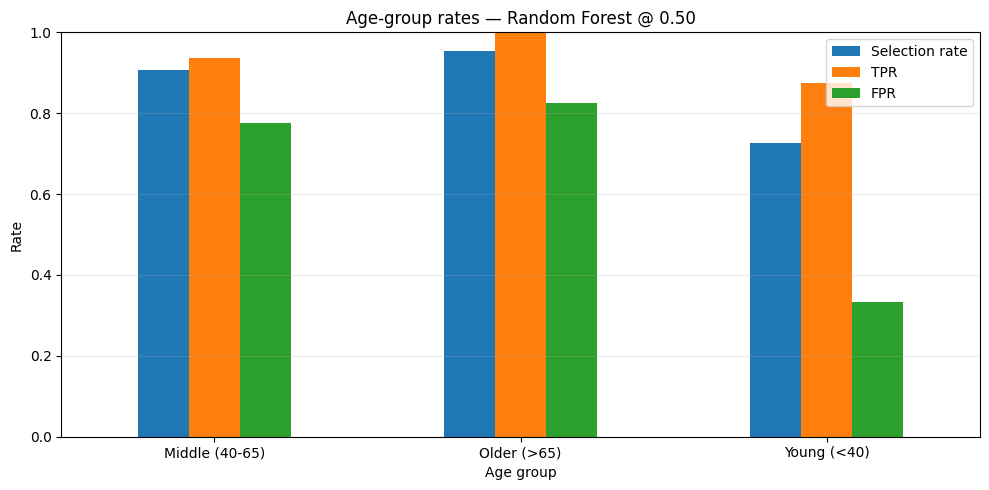

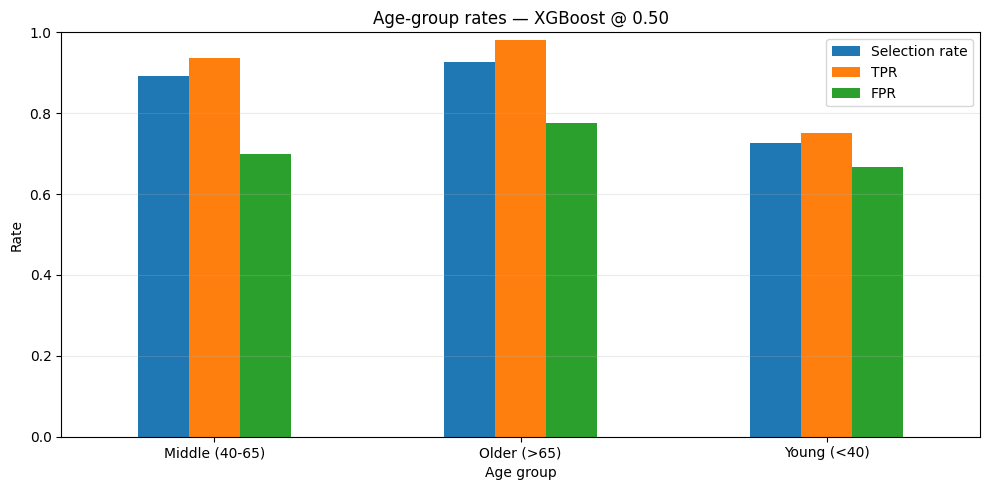

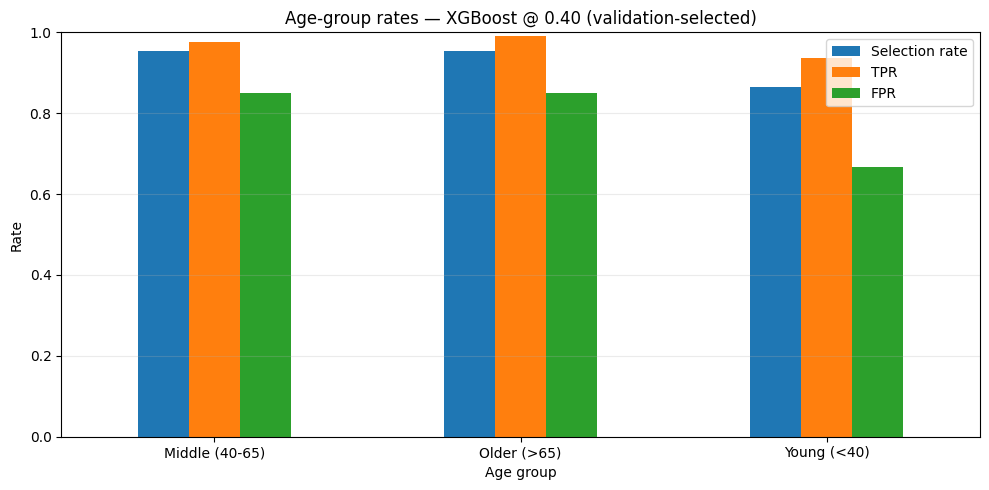

In [8]:
display(AGE_METRICS)
for model in AGE_METRICS['Model'].dropna().unique():
    sub=AGE_METRICS[AGE_METRICS['Model']==model]
    ax=sub.set_index('Age group')[['Selection rate','TPR','FPR']].plot(kind='bar',figsize=(10,5),ylim=(0,1))
    ax.set_title(f'Age-group rates — {model}'); ax.set_ylabel('Rate'); ax.tick_params(axis='x',rotation=0); ax.grid(axis='y',alpha=.25); plt.tight_layout(); plt.show()

## 9. Paired bootstrap confidence intervals

,Metric,Threshold 0.50 estimate,Selected threshold,Selected threshold estimate,Difference selected minus 0.50,Paired bootstrap 95% CI lower,Paired bootstrap 95% CI upper,Bootstrap proportion difference < 0,Replicates,Seed
0,DPD,0.198902,0.4,0.089415,-0.109486,-0.252593,0.025221,0.9311,10000,42
1,EOD,0.231651,0.4,0.183333,-0.048318,-0.299159,0.150000,0.5622,10000,42


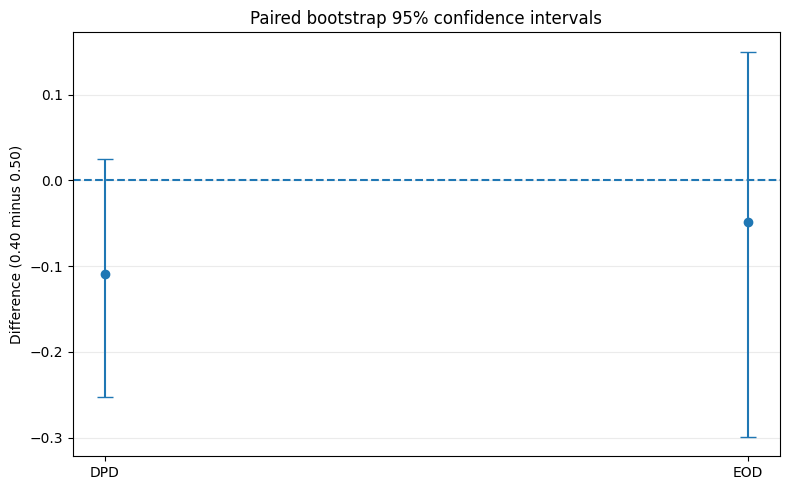

Both 95% CIs include zero; these results do not establish a statistically conclusive fairness improvement.


In [9]:
display(BOOTSTRAP_CI)
fig,ax=plt.subplots(figsize=(8,5))
x=np.arange(len(BOOTSTRAP_CI)); est=BOOTSTRAP_CI['Difference selected minus 0.50'].to_numpy(); lo=BOOTSTRAP_CI['Paired bootstrap 95% CI lower'].to_numpy(); hi=BOOTSTRAP_CI['Paired bootstrap 95% CI upper'].to_numpy()
ax.errorbar(x,est,yerr=np.vstack([est-lo,hi-est]),fmt='o',capsize=6); ax.axhline(0,ls='--'); ax.set_xticks(x,BOOTSTRAP_CI['Metric']); ax.set_ylabel('Difference (0.40 minus 0.50)'); ax.set_title('Paired bootstrap 95% confidence intervals'); ax.grid(axis='y',alpha=.25); plt.tight_layout(); plt.show()
print('Both 95% CIs include zero; these results do not establish a statistically conclusive fairness improvement.')

## 10. Clinical error trade-off

In [10]:
rows=[]
for name,prob,t in runs:
    tn,fp,fn,tp=confusion_matrix(y_test,labels_at(prob,t),labels=[0,1]).ravel()
    rows.append({'Model / threshold':name,'TN':tn,'FP':fp,'FN':fn,'TP':tp,'Sensitivity / TPR':tp/(tp+fn),'Specificity':tn/(tn+fp),'FPR':fp/(fp+tn)})
tradeoff=pd.DataFrame(rows); display(tradeoff.style.format({'Sensitivity / TPR':'{:.3f}','Specificity':'{:.3f}','FPR':'{:.3f}'}))

,Model / threshold,TN,FP,FN,TP,Sensitivity / TPR,Specificity,FPR
0,Logistic Regression @ 0.50,14,72,7,291,0.977,0.163,0.837
1,Random Forest @ 0.50,20,66,13,285,0.956,0.233,0.767
2,XGBoost @ 0.50,23,63,17,281,0.943,0.267,0.733
3,XGBoost @ 0.40 (validation-selected),14,72,6,292,0.980,0.163,0.837


## 11. Interpretation and limitations

- The positive class is observed overall survival of at least 60 months; this is not cancer-specific survival.
- Threshold 0.40 is asingle global threshold, selected on validation data, not separate thresholds for each age group.
- Lowering the threshold reduces false negatives but increases false positives; false-positive survival predictions may create false reassurance.
- Both paired-bootstrap 95% confidence intervals include zero, so do not claim a statistically established fairness improvement.
- The young age subgroup is small, so subgroup rates can be unstable.
